In [86]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [87]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]


# Filtering data frame to have only the data analyst role and mena countries
df_mena_DA = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short']=='Data Analyst') & (df['job_skills'].notna())]

for countries in mena_countries:
    if countries not in df_mena_DA['job_country'].unique():
        print(countries)
# There are no job postings from Syria and Libya for the Data Analyst role

Libya
Syria


In [88]:
# Making a new column for month number for the chronological anlysis
df_mena_DA['job_month_no'] = df_mena_DA['job_posted_date'].dt.month


In [89]:
df_mena_DA_explode = df_mena_DA.explode('job_skills') 

In [90]:
df_mena_DA_pivot = df_mena_DA_explode.pivot_table(index = 'job_month_no', columns = 'job_skills', aggfunc= 'size', fill_value=  0)

In [91]:
# creating a total column to sort skills with it
df_mena_DA_pivot.loc['Total'] = df_mena_DA_pivot.sum()


In [92]:
df_mena_DA_pivot = df_mena_DA_pivot[df_mena_DA_pivot.loc['Total'].sort_values(ascending=False).index]
df_mena_DA_pivot = df_mena_DA_pivot.drop('Total')


In [93]:
df_job_posts_per_month = df_mena_DA.groupby('job_month_no').size()
df_job_posts_per_month

job_month_no
1     613
2     364
3     355
4     334
5     270
6     336
7     376
8     627
9     479
10    578
11    472
12    359
dtype: int64

In [94]:
df_mena_DA_perc = df_mena_DA_pivot.div(df_job_posts_per_month/100, axis = 0)

In [95]:
df_mena_DA_perc = df_mena_DA_perc.reset_index()
df_mena_DA_perc['job_posted_month'] = df_mena_DA_perc['job_month_no'].apply(lambda x: pd.to_datetime(x,format= '%m').strftime('%b'))
df_mena_DA_perc = df_mena_DA_perc.set_index('job_posted_month')
df_mena_DA_perc = df_mena_DA_perc.drop(columns = 'job_month_no')

In [100]:
df_plot = df_mena_DA_perc.iloc[:,:5]

Text(0, 0.5, 'Likelihood In Job Posting')

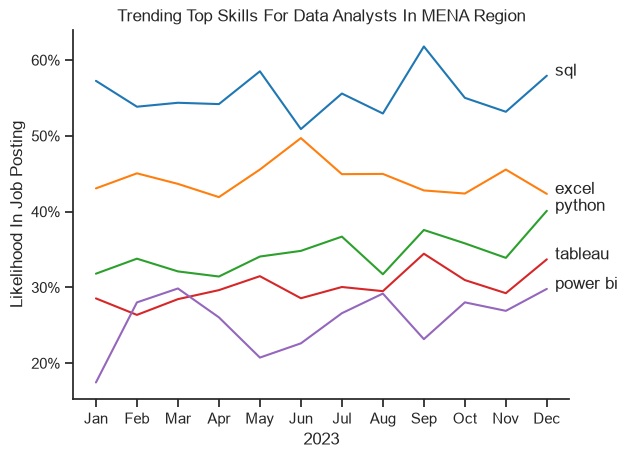

In [113]:
sns.lineplot(data = df_plot, dashes = False, palette = 'tab10')
sns.set_theme(style = 'ticks')
sns.despine()

for i in range(5):
    plt.text(11.2,df_plot.iloc[-1,i],df_plot.columns[i])

from matplotlib.ticker import PercentFormatter

ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals= 0))

plt.title('Trending Top Skills For Data Analysts In MENA Region')
plt.legend().remove()
plt.xlabel('2023')
plt.ylabel('Likelihood In Job Posting')
